# Control dataset summary

This notebook summarizes the control candidates by control category, formula skeleton, space group, stability, theoretical status, and selected numerical properties.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path('/Users/andrewweiland/Andrews_Lab_Research/electride-ml-predictor')
DATA_PATH = PROJECT_ROOT / 'data/control/final_dataset/control_dataset.csv'
df = pd.read_csv(DATA_PATH)

# Give overlapping records one exclusive category for clean counts.
def category(control_type):
    if 'broad_background' in control_type:
        return 'Broad background'
    if 'isostructural_chemical' in control_type:
        return 'Isostructural chemical'
    return 'Same skeleton + space group'

df['control_category'] = df['control_type'].map(category)
for column in ['space_group', 'formula_skeleton', 'crystal_system']:
    df[column] = df[column].fillna('Not reported')

print(f'Structures: {len(df):,}')
print(f'Unique MP IDs: {df["mp_id"].nunique():,}')
print(f'Unique formula skeletons: {df["formula_skeleton"].nunique():,}')
print(f'Unique space groups: {df["space_group"].nunique():,}')
df.head()

Structures: 716
Unique MP IDs: 716
Unique formula skeletons: 94
Unique space groups: 84


,mp_id,formula,formula_skeleton,space_group,space_group_number,crystal_system,n_sites,volume_A3,energy_above_hull_eV_per_atom,band_gap_eV,is_stable,theoretical,control_type,seed_mp_id,control_category
0,mp-7188,Al2Os,AB2,I4/mmm,139,Tetragonal,3.0,41.330408,0.0,0.2899,True,False,same_formula_skeleton_and_space_group,mp-2768,Same skeleton + space group
1,mp-10909,AlRe2,AB2,I4/mmm,139,Tetragonal,3.0,42.767474,0.0,0.0000,True,False,same_formula_skeleton_and_space_group,mp-2768,Same skeleton + space group
2,mp-1018166,AlTc2,AB2,I4/mmm,139,Tetragonal,3.0,41.784698,0.0,0.0000,True,False,same_formula_skeleton_and_space_group,mp-2768,Same skeleton + space group
3,mp-8093,Ba2Cd,AB2,I4/mmm,139,Tetragonal,3.0,142.169222,0.0,0.0000,True,False,same_formula_skeleton_and_space_group,mp-2768,Same skeleton + space group
4,mp-8094,Ba2Hg,AB2,I4/mmm,139,Tetragonal,3.0,137.307651,0.0,0.0000,True,False,same_formula_skeleton_and_space_group,mp-2768,Same skeleton + space group


In [2]:
print('Control categories')
display(df['control_category'].value_counts().rename('structure_count').to_frame())

print('Most common formula skeletons')
display(df['formula_skeleton'].value_counts().head(25).rename('structure_count').to_frame())

print('Most common space groups')
display(df['space_group'].value_counts().head(25).rename('structure_count').to_frame())

print('Stability')
display(df['is_stable'].value_counts(dropna=False).rename('structure_count').to_frame())

print('Theoretical status')
display(df['theoretical'].value_counts(dropna=False).rename('structure_count').to_frame())

Control categories


,structure_count
control_category,
Same skeleton + space group,363
Broad background,300
Isostructural chemical,53


Most common formula skeletons


,structure_count
formula_skeleton,
AB2,88
AB3,77
A3B5,75
AB,49
ABC2,47
A2B5,46
ABC4,38
ABC,34
AB6C12,20


Most common space groups


,structure_count
space_group,
Pnma,102
Fm-3m,61
Cmcm,59
C2/c,54
Pm-3m,40
I4/mmm,34
F-43m,34
I4/mcm,29
Fd-3m,26


Stability


,structure_count
is_stable,
True,682
False,34


Theoretical status


,structure_count
theoretical,
False,530
True,186


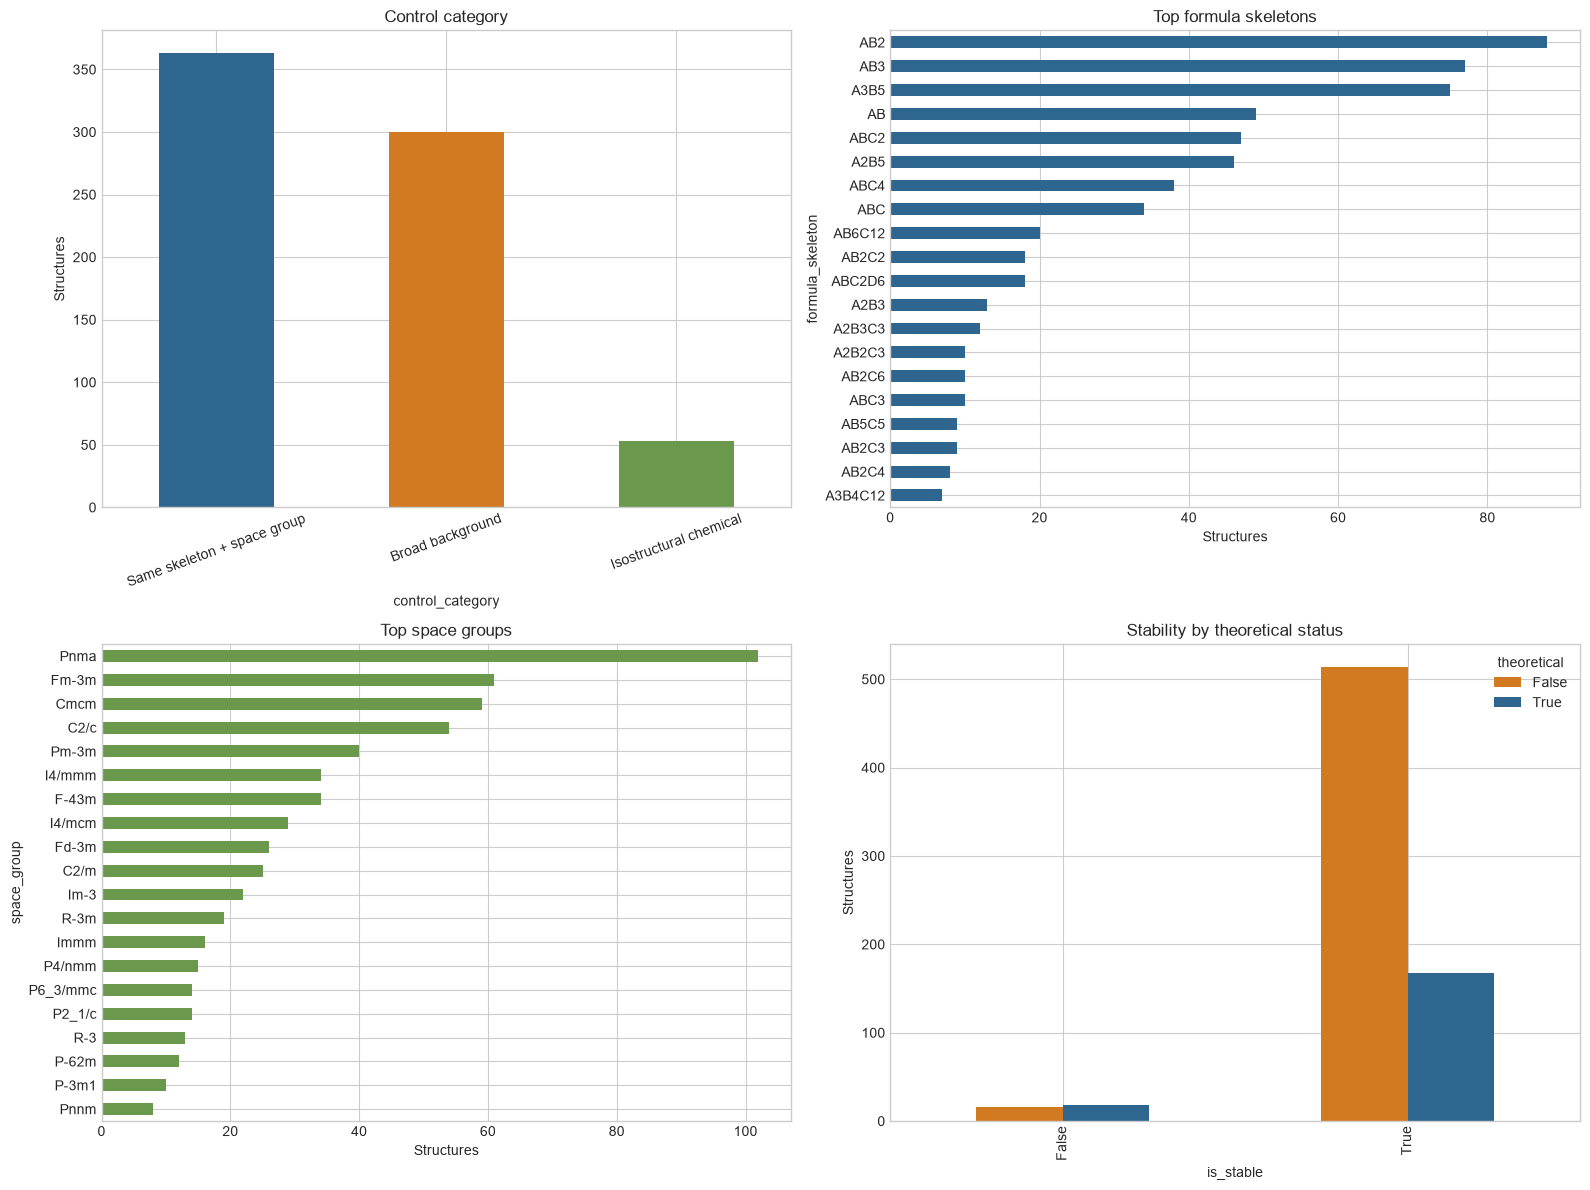

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
colors = ['#2f6690', '#d17a22', '#6a994e']

df['control_category'].value_counts().plot.bar(ax=axes[0, 0], color=colors)
axes[0, 0].set_title('Control category')
axes[0, 0].set_ylabel('Structures')
axes[0, 0].tick_params(axis='x', rotation=20)

df['formula_skeleton'].value_counts().head(20).sort_values().plot.barh(ax=axes[0, 1], color='#2f6690')
axes[0, 1].set_title('Top formula skeletons')
axes[0, 1].set_xlabel('Structures')

df['space_group'].value_counts().head(20).sort_values().plot.barh(ax=axes[1, 0], color='#6a994e')
axes[1, 0].set_title('Top space groups')
axes[1, 0].set_xlabel('Structures')

pd.crosstab(df['is_stable'].astype(str), df['theoretical'].astype(str)).plot.bar(ax=axes[1, 1], color=['#d17a22', '#2f6690'])
axes[1, 1].set_title('Stability by theoretical status')
axes[1, 1].set_xlabel('is_stable')
axes[1, 1].set_ylabel('Structures')
axes[1, 1].legend(title='theoretical')
plt.tight_layout()
plt.show()

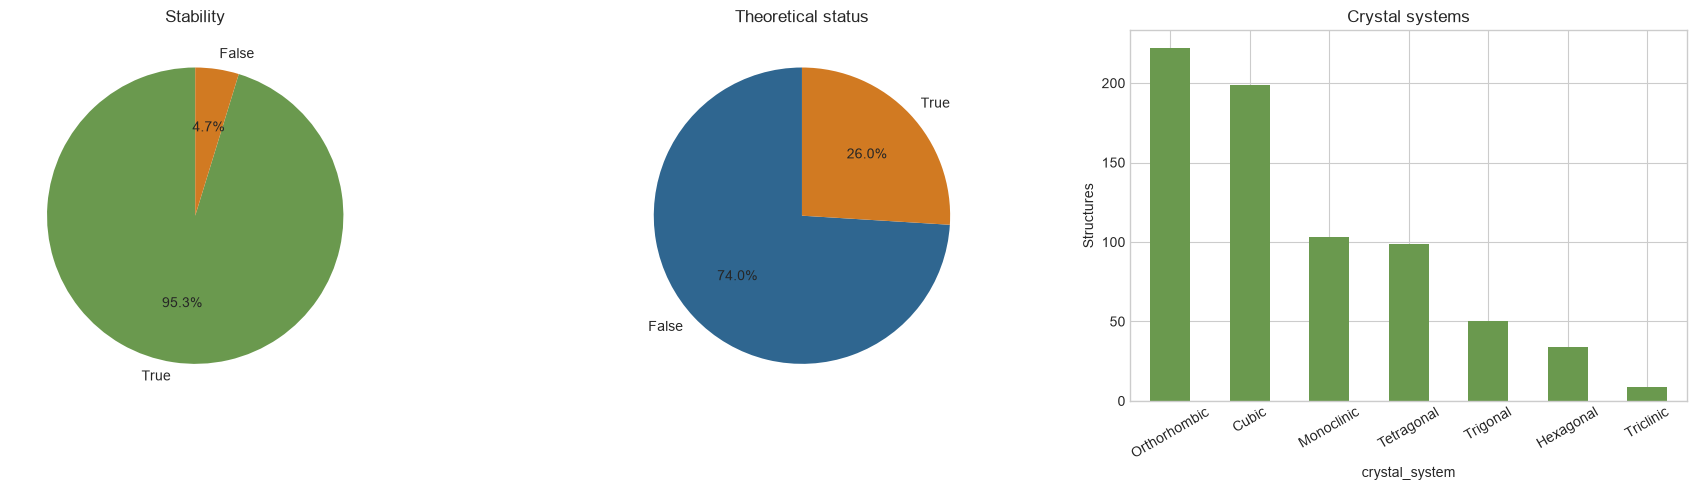

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['is_stable'].astype(str).value_counts().plot.pie(ax=axes[0], autopct='%1.1f%%', startangle=90, colors=['#6a994e', '#d17a22'])
axes[0].set_title('Stability')
axes[0].set_ylabel('')

df['theoretical'].astype(str).value_counts().plot.pie(ax=axes[1], autopct='%1.1f%%', startangle=90, colors=['#2f6690', '#d17a22'])
axes[1].set_title('Theoretical status')
axes[1].set_ylabel('')

df['crystal_system'].value_counts().plot.bar(ax=axes[2], color='#6a994e')
axes[2].set_title('Crystal systems')
axes[2].set_ylabel('Structures')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

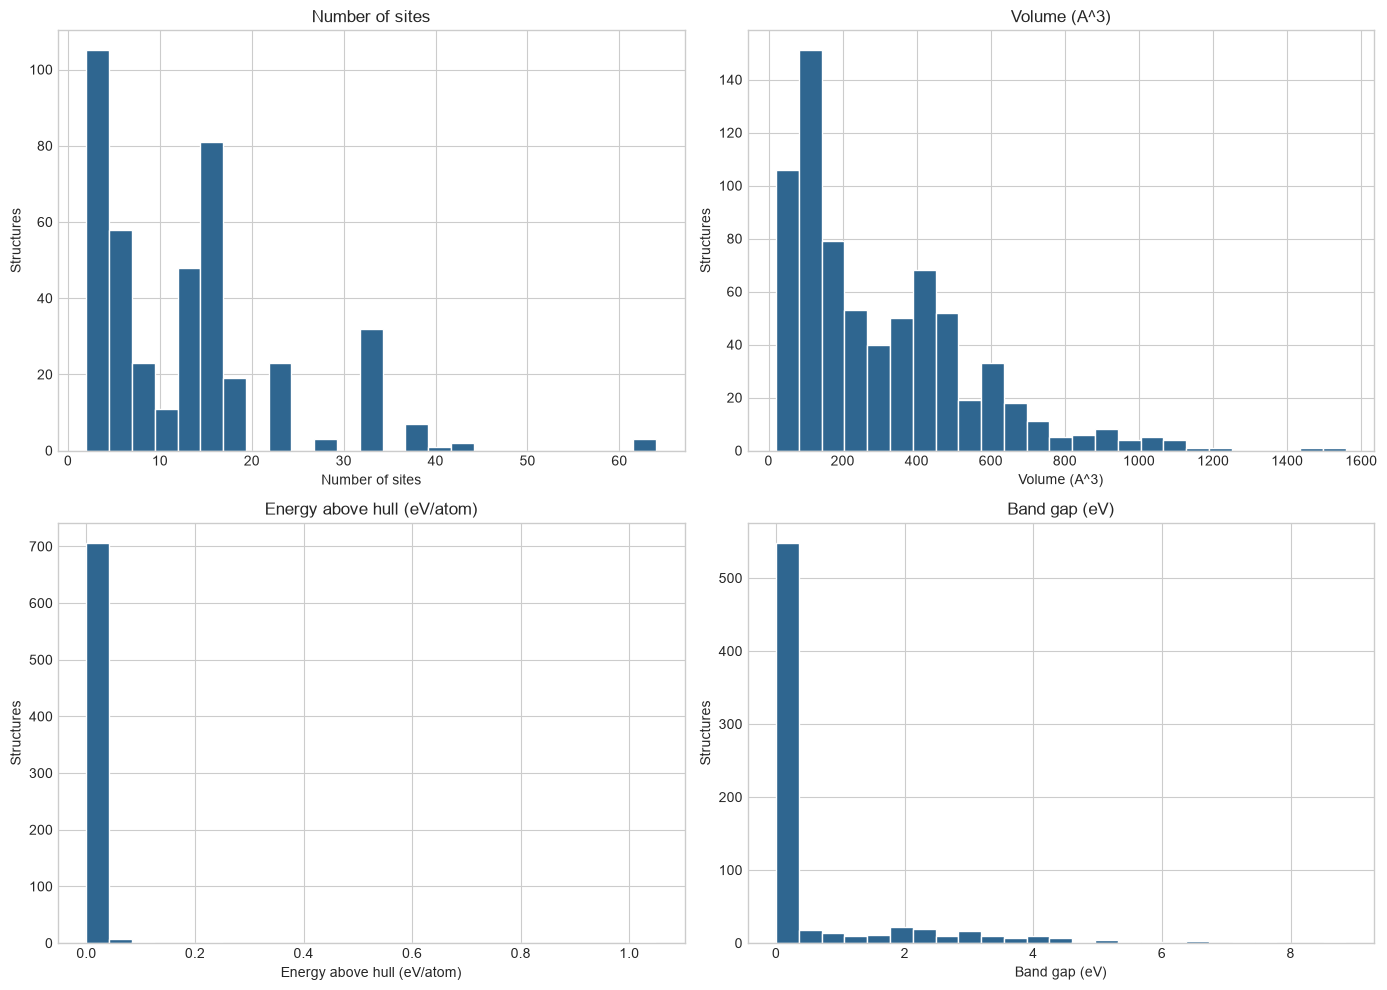

Numeric summary


,count,mean,std,min,25%,50%,75%,max
n_sites,416.0,13.358173,10.249611,2.000000,4.000000,14.000000,16.000000,64.000000
volume_A3,716.0,304.113883,243.166684,20.218611,106.518826,233.372051,444.836064,1558.303627
energy_above_hull_eV_per_atom,716.0,0.002971,0.040777,0.000000,0.000000,0.000000,0.000000,1.049582
band_gap_eV,716.0,0.607422,1.334245,0.000000,0.000000,0.000000,0.090025,8.859000


In [5]:
numeric_columns = {
    'n_sites': 'Number of sites',
    'volume_A3': 'Volume (A^3)',
    'energy_above_hull_eV_per_atom': 'Energy above hull (eV/atom)',
    'band_gap_eV': 'Band gap (eV)',
}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, (column, title) in zip(axes.flat, numeric_columns.items()):
    values = pd.to_numeric(df[column], errors='coerce').dropna()
    axis.hist(values, bins=25, color='#2f6690', edgecolor='white')
    axis.set_title(title)
    axis.set_ylabel('Structures')
    axis.set_xlabel(title)
plt.tight_layout()
plt.show()

print('Numeric summary')
display(df[list(numeric_columns)].apply(pd.to_numeric, errors='coerce').describe().T)